In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("Genre Classification Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

PermissionError: [Errno 13] Permission denied: 'Genre Classification Dataset.csv'

In [6]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\krishna\Documents\Python codes\Movie_Genre_Classification
['Genre Classification Dataset.csv', 'Movie_Genre_Classification.ipynb']


In [7]:
import os

file_path = "Genre Classification Dataset.csv"

print("File exists:", os.path.isfile(file_path))
print("Is folder:", os.path.isdir(file_path))
print("File size:", os.path.getsize(file_path) if os.path.isfile(file_path) else "Not a file")

File exists: False
Is folder: True
File size: Not a file


In [8]:
import pandas as pd

train_path = "Genre Classification Dataset.csv/train_data.txt"

train_df = pd.read_csv(
    train_path,
    sep=" ::: ",
    engine="python",
    names=["ID", "TITLE", "GENRE", "DESCRIPTION"]
)

print("Dataset loaded successfully!")
print("Shape:", train_df.shape)
train_df.head()

Dataset loaded successfully!
Shape: (54214, 4)


,ID,TITLE,GENRE,DESCRIPTION
0,1,Oscar et la dame rose (2009),drama,Listening in to a conversation between his doc...
1,2,Cupid (1997),thriller,A brother and sister with a past incestuous re...
2,3,"Young, Wild and Wonderful (1980)",adult,As the bus empties the students for their fiel...
3,4,The Secret Sin (1915),drama,To help their unemployed father make ends meet...
4,5,The Unrecovered (2007),drama,The film's title refers not only to the un-rec...


In [9]:
print("Dataset Shape:", train_df.shape)
print("\nColumn Names:")
print(train_df.columns.tolist())

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nGenre Distribution:")
print(train_df["GENRE"].value_counts())

print("\nDuplicate Rows:", train_df.duplicated().sum())

Dataset Shape: (54214, 4)

Column Names:
['ID', 'TITLE', 'GENRE', 'DESCRIPTION']

Missing Values:
ID             0
TITLE          0
GENRE          0
DESCRIPTION    0
dtype: int64

Genre Distribution:
GENRE
drama          13613
documentary    13096
comedy          7447
short           5073
horror          2204
thriller        1591
action          1315
western         1032
reality-tv       884
family           784
adventure        775
music            731
romance          672
sci-fi           647
adult            590
crime            505
animation        498
sport            432
talk-show        391
fantasy          323
mystery          319
musical          277
biography        265
history          243
game-show        194
news             181
war              132
Name: count, dtype: int64

Duplicate Rows: 0


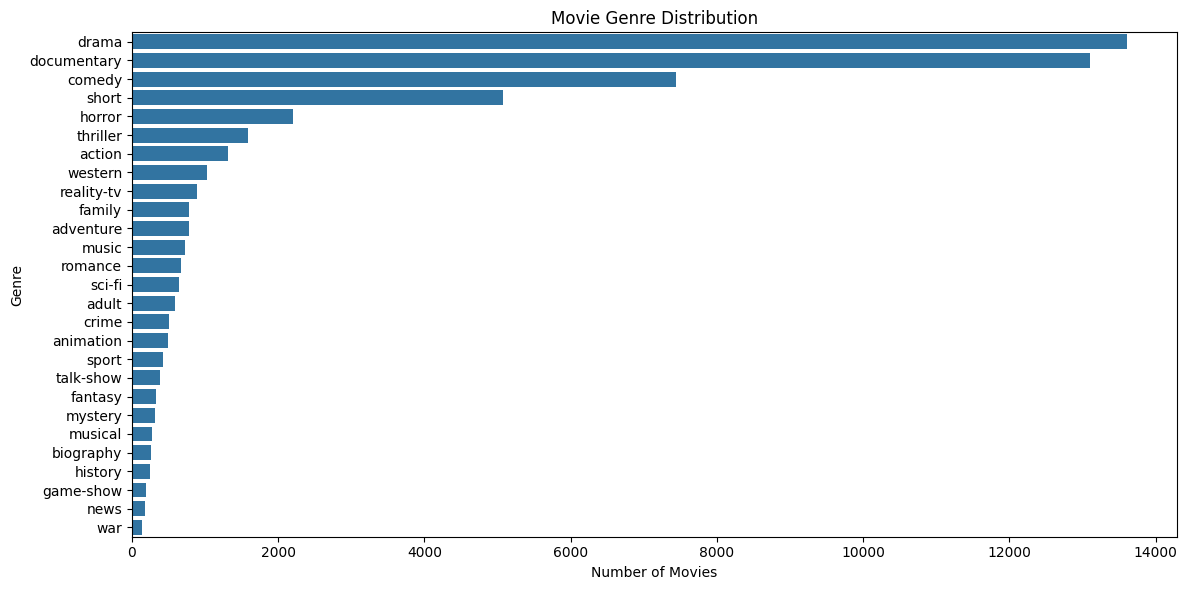

In [10]:
plt.figure(figsize=(12, 6))

genre_counts = train_df["GENRE"].value_counts()

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Movie Genre Distribution")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [11]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["CLEAN_DESCRIPTION"] = train_df["DESCRIPTION"].apply(clean_text)

print("Text preprocessing completed!")
train_df[["DESCRIPTION", "CLEAN_DESCRIPTION", "GENRE"]].head()

Text preprocessing completed!


,DESCRIPTION,CLEAN_DESCRIPTION,GENRE
0,Listening in to a conversation between his doc...,listening in to a conversation between his doc...,drama
1,A brother and sister with a past incestuous re...,a brother and sister with a past incestuous re...,thriller
2,As the bus empties the students for their fiel...,as the bus empties the students for their fiel...,adult
3,To help their unemployed father make ends meet...,to help their unemployed father make ends meet...,drama
4,The film's title refers not only to the un-rec...,the films title refers not only to the unrecov...,drama


In [ ]:
X = train_df["CLEAN_DESCRIPTION"]
y = train_df["GENRE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 43371
Testing samples: 10843


In [13]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF Vectorization completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

TF-IDF Vectorization completed!
Training matrix shape: (43371, 50000)
Testing matrix shape: (10843, 50000)


In [ ]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

print("Training model...")

model.fit(X_train_tfidf, y_train)

print("Model training completed successfully!")

Training model...
Model training completed successfully!


In [ ]:
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 57.99 %


In [16]:
#print("Classification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

      action       0.60      0.22      0.33       263
       adult       0.75      0.28      0.41       118
   adventure       0.77      0.11      0.19       155
   animation       0.75      0.03      0.06       100
   biography       0.00      0.00      0.00        53
      comedy       0.53      0.59      0.56      1490
       crime       0.25      0.01      0.02       101
 documentary       0.65      0.87      0.75      2619
       drama       0.53      0.80      0.64      2723
      family       0.74      0.09      0.16       157
     fantasy       0.00      0.00      0.00        65
   game-show       1.00      0.33      0.50        39
     history       0.00      0.00      0.00        49
      horror       0.69      0.54      0.60       441
       music       0.70      0.36      0.47       146
     musical       0.00      0.00      0.00        55
     mystery       0.00      0.00      0.00        64
        news       0.00    

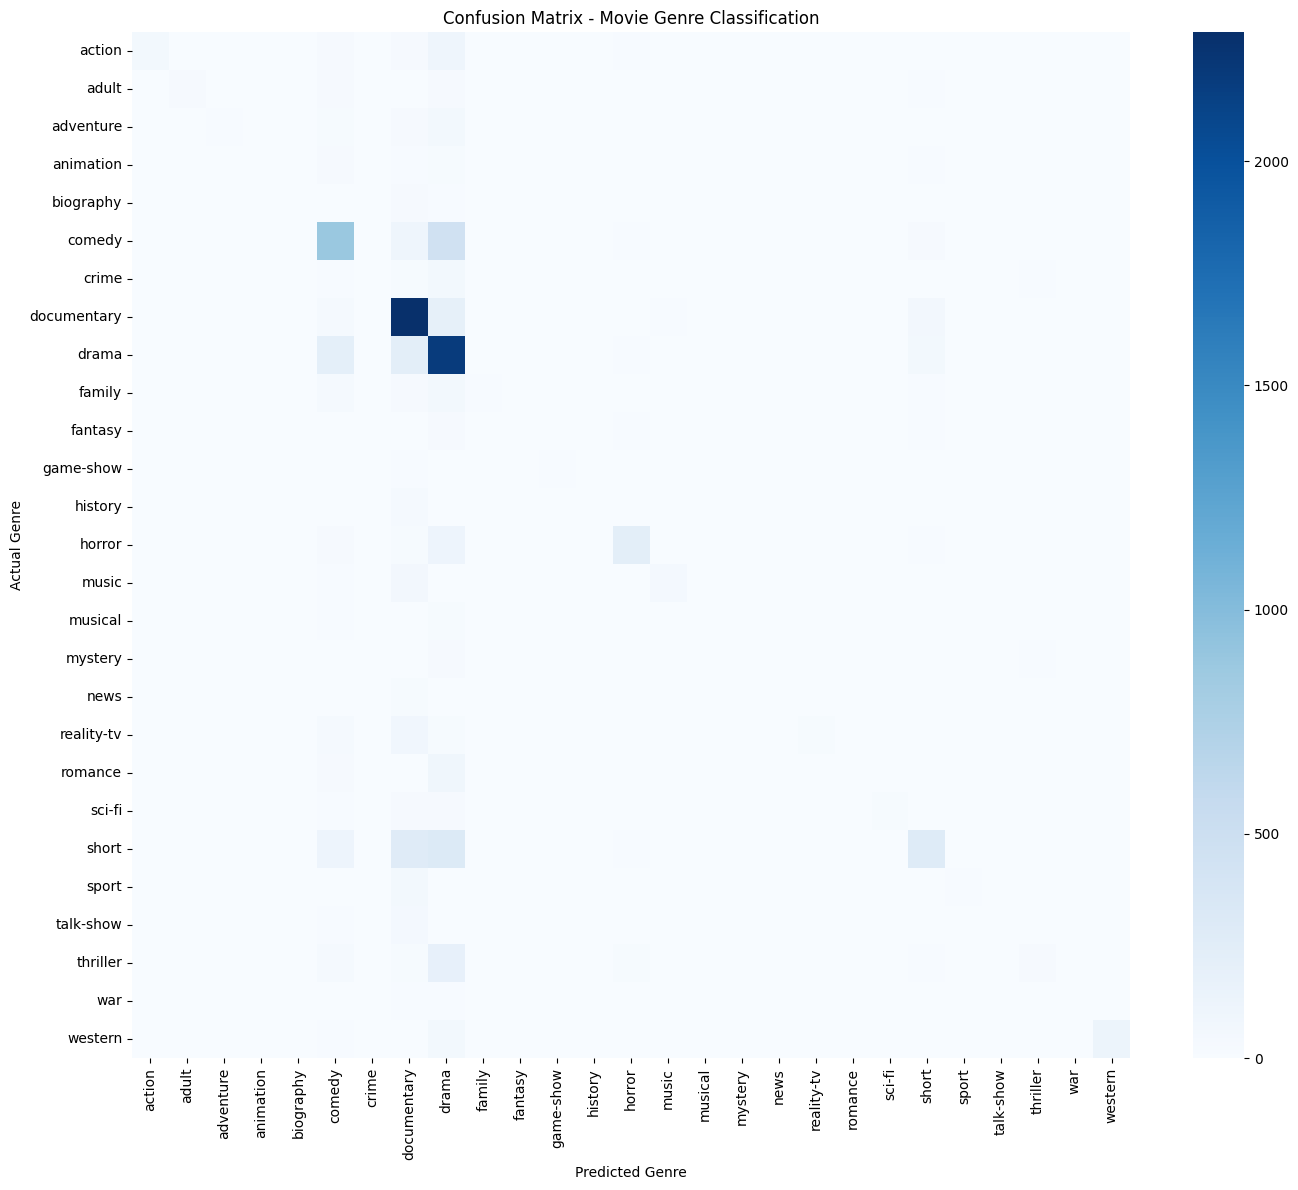

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(14, 12))

sns.heatmap(
    cm,
    annot=False,
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Confusion Matrix - Movie Genre Classification")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
train_df["TEXT"] = (
    train_df["TITLE"].fillna("") + " " +
    train_df["CLEAN_DESCRIPTION"].fillna("")
)

X = train_df["TEXT"]
y = train_df["GENRE"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Title + Description combined successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Title + Description combined successfully!
Training samples: 43371
Testing samples: 10843


In [19]:

tfidf_improved = TfidfVectorizer(
    max_features=60000,
    stop_words="english",
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf_improved.fit_transform(X_train)
X_test_tfidf = tfidf_improved.transform(X_test)

print("Improved TF-IDF completed!")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Improved TF-IDF completed!
Training matrix shape: (43371, 60000)
Testing matrix shape: (10843, 60000)


In [20]:
model_improved = LogisticRegression(
    max_iter=1500,
    C=2.0,
    random_state=42
)

print("Training improved model...")

model_improved.fit(X_train_tfidf, y_train)

print("Improved model training completed!")

Training improved model...
Improved model training completed!


In [21]:
y_pred_improved = model_improved.predict(X_test_tfidf)

accuracy_improved = accuracy_score(y_test, y_pred_improved)

print("Improved Model Accuracy:", round(accuracy_improved * 100, 2), "%")

Improved Model Accuracy: 59.81 %


In [22]:
print("Improved Model Classification Report:\n")
print(classification_report(
    y_test,
    y_pred_improved,
    zero_division=0
))

Improved Model Classification Report:

              precision    recall  f1-score   support

      action       0.54      0.29      0.38       263
       adult       0.73      0.32      0.45       118
   adventure       0.60      0.14      0.22       155
   animation       0.44      0.07      0.12       100
   biography       0.00      0.00      0.00        53
      comedy       0.54      0.61      0.57      1490
       crime       0.20      0.01      0.02       101
 documentary       0.68      0.87      0.76      2619
       drama       0.55      0.78      0.65      2723
      family       0.68      0.11      0.19       157
     fantasy       0.00      0.00      0.00        65
   game-show       0.94      0.44      0.60        39
     history       0.00      0.00      0.00        49
      horror       0.71      0.61      0.65       441
       music       0.73      0.44      0.55       146
     musical       0.50      0.02      0.04        55
     mystery       0.67      0.03      0.0

In [23]:
print("MODEL COMPARISON")
print("-" * 40)

print(f"Baseline Model Accuracy : {accuracy * 100:.2f}%")
print(f"Improved Model Accuracy : {accuracy_improved * 100:.2f}%")

improvement = (accuracy_improved - accuracy) * 100

print(f"Improvement             : {improvement:.2f}%")

MODEL COMPARISON
----------------------------------------
Baseline Model Accuracy : 57.99%
Improved Model Accuracy : 59.81%
Improvement             : 1.82%


In [25]:
def predict_genre(movie_title, movie_description):
    text = movie_title + " " + movie_description
    
    cleaned_text = clean_text(text)
    
    text_vector = tfidf_improved.transform([cleaned_text])
    
    prediction = model_improved.predict(text_vector)[0]
    
    return prediction




title = "The Haunted House"
description = "A group of friends enters an abandoned house and discovers a terrifying supernatural presence."

predicted_genre = predict_genre(title, description)

print("Movie Title:", title)
print("Predicted Genre:", predicted_genre)

Movie Title: The Haunted House
Predicted Genre: horror


In [26]:
import joblib

# Save trained model and TF-IDF vectorizer

joblib.dump(model_improved, "movie_genre_model.pkl")
joblib.dump(tfidf_improved, "movie_genre_tfidf.pkl")

print("Model saved successfully!")
print("TF-IDF vectorizer saved successfully!")

Model saved successfully!
TF-IDF vectorizer saved successfully!


In [27]:
test_movies = [
    (
        "The Haunted House",
        "A group of friends enters an abandoned house and discovers a terrifying supernatural presence."
    ),
    (
        "The Final Match",
        "A talented young player struggles to win the championship while overcoming many challenges."
    ),
    (
        "Love in Paris",
        "Two strangers meet in Paris and slowly fall in love while exploring the beautiful city together."
    ),
    (
        "The Secret Mission",
        "A trained agent is sent on a dangerous mission to stop an international criminal organization."
    )
]

for title, description in test_movies:
    prediction = predict_genre(title, description)
    print(f"Movie: {title}")
    print(f"Predicted Genre: {prediction}")
    print("-" * 50)

Movie: The Haunted House
Predicted Genre: horror
--------------------------------------------------
Movie: The Final Match
Predicted Genre: sport
--------------------------------------------------
Movie: Love in Paris
Predicted Genre: romance
--------------------------------------------------
Movie: The Secret Mission
Predicted Genre: action
--------------------------------------------------


In [28]:
print("=" * 60)
print("       MOVIE GENRE CLASSIFICATION - FINAL RESULTS")
print("=" * 60)

print(f"\nDataset Size          : {len(train_df):,} movies")
print(f"Number of Genres      : {train_df['GENRE'].nunique()}")
print(f"Baseline Accuracy     : {accuracy * 100:.2f}%")
print(f"Improved Accuracy     : {accuracy_improved * 100:.2f}%")
print(f"Improvement           : {(accuracy_improved - accuracy) * 100:.2f}%")

print("\nModel                 : Logistic Regression")
print("Feature Extraction    : TF-IDF")
print("Features Used         : Movie Title + Description")
print("Task                  : Multi-Class Genre Classification")

print("\n" + "=" * 60)
print("Project completed successfully!")
print("=" * 60)

       MOVIE GENRE CLASSIFICATION - FINAL RESULTS

Dataset Size          : 54,214 movies
Number of Genres      : 27
Baseline Accuracy     : 57.99%
Improved Accuracy     : 59.81%
Improvement           : 1.82%

Model                 : Logistic Regression
Feature Extraction    : TF-IDF
Features Used         : Movie Title + Description
Task                  : Multi-Class Genre Classification

Project completed successfully!
